# YOLOv8n — Final Model Training + One-Time Independent Test (Google Colab)

Companion to the leak-free 5-fold CV notebook. It trains the **single final YOLOv8n model** that is
reported in the paper and deployed on the Dragon Q6A, using **exactly the CV recipe**:

| Setting | Value (identical to CV) |
|---|---|
| Start weights | `yolov8n.pt` (COCO pretrained) |
| Epochs / patience | 50 / 20 |
| Image size / batch | 640 / 32 |
| Augmentation | Ultralytics defaults only (no synthetic / copy-paste data) |
| Deterministic | yes |
| Ultralytics | 8.4.173 |

### Protocol
1. Development pool = original `train/` + `valid/` (1,091 images). The 42-image `test/` split is used **only** in Section 8.
2. A fresh grouped split of the development pool (seed 42 + 999, ~80/20) gives train / validation. Validation is used only to pick `best.pt`.
3. `best.pt` is evaluated **once** on the 42-image test set. A lock file on Drive prevents accidental re-evaluation.
4. Test metrics are reported with **bootstrap 95% confidence intervals** (image-level resampling).
5. The same `best.pt` is exported to static ONNX (1×3×640×640), checked against PyTorch, and 200 calibration
   images from the *final training split* are saved for INT8 / QNN conversion.

### Do NOT pick one of the 5 CV fold models
CV estimates how well the *recipe* works. The deployed model is this one, trained on more data and never
selected by held-out or test score.

### Outputs (persisted on Google Drive)
`MyDrive/ganoderma/experiments/final_yolov8n_v1/` → `best.pt`, `last.pt`, manifests, `train_run/`,
`val_metrics.json`, `TEST_EVAL_LOCK.json` (test metrics + CIs), `onnx/`, `calibration_images/`, `final_summary.json`.

**Runtime (Colab T4):** ~10–15 min training + a few minutes for audit, test, export.
Run `SMOKE_TEST = True` first if you want a quick end-to-end pipeline check (writes to a separate `_smoke` folder).

In [1]:
# ============================================================
# 0. INSTALL DEPENDENCIES
# ============================================================
!pip -q install "ultralytics==8.4.173" "scikit-learn>=1.4" "ImageHash>=4.3" pyyaml tqdm onnx onnxslim onnxruntime

import ultralytics, torch
print("Ultralytics:", ultralytics.__version__, "| PyTorch:", torch.__version__)
assert ultralytics.__version__ == "8.4.173", "Pin ultralytics to 8.4.173 (same as the CV experiment)"
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not available. In Colab choose Runtime > Change runtime type > GPU, "
        "then reconnect your VS Code Colab session."
    )
print("GPU:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 122.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.8/245.8 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 103.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.173 | PyTorch: 2.11.0+cu130
GPU: NVIDIA A100-SXM4-40GB


In [2]:
# ============================================================
# 1. MOUNT DRIVE + CONFIGURATION
# ============================================================
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

# ------------------------------
# Dataset location (same as the CV notebook)
# ------------------------------
DATASET_ROOT = Path("/content/drive/MyDrive/ganoderma")

if (DATASET_ROOT / "valid").exists():
    VAL_FOLDER_NAME = "valid"
elif (DATASET_ROOT / "val").exists():
    VAL_FOLDER_NAME = "val"
else:
    raise FileNotFoundError(f"Could not find {DATASET_ROOT / 'valid'} or {DATASET_ROOT / 'val'}")

# ------------------------------
# Experiment output (persistent, on Drive)
# ------------------------------
EXP_NAME = "final_yolov8n_v1"

# CV experiments whose dataset audit can be reused (first match with identical counts wins).
CV_EXPS_FOR_AUDIT = ["leak_free_yolov8s_lite_cv_v1", "leak_free_yolov8s_cv_v1"]

LOCAL_DATASET = Path("/content/ganoderma_source")      # fast local copy of original data
LOCAL_WORK    = Path("/content/ganoderma_final_work")  # local training workspace

# ------------------------------
# Training recipe — keep IDENTICAL to the CV experiment
# ------------------------------
SEED       = 42
FINAL_SEED = SEED + 999
MODEL_CFG  = "yolov8n.pt"
EPOCHS     = 50
IMGSZ      = 640
BATCH      = 32
PATIENCE   = 20
WORKERS    = 2
DEVICE     = 0

# Validation share of the development pool: 1 / VAL_SPLITS  (5 -> ~80/20, same ratio as CV inner split)
VAL_SPLITS = 5

# Leak grouping for the train/val split:
#   "exact" = identical pHash only (SAME as the CV notebook -> recipe consistency)
#   "near"  = also groups near-duplicates (Hamming <= NEAR_HAMMING) and flipped copies
#             (stricter; cleaner validation for checkpoint selection)
GROUPING     = "exact"
NEAR_HAMMING = 8

# ------------------------------
# Evaluation / export
# ------------------------------
RUN_TEST_EVAL     = True    # one-time evaluation on the 42-image independent test set
ALLOW_TEST_REEVAL = False   # keep False: protects the one-shot test protocol
EVAL_CONF   = 0.001         # retained-prediction threshold (same as the paper protocol)
EVAL_IOU    = 0.70          # NMS IoU
EVAL_MAXDET = 300
N_BOOTSTRAP = 2000
CALIB_N     = 200           # calibration images for INT8 / QNN (from the final TRAIN split only)
ONNX_OPSET  = 12            # set to the opset your onnx2qnn / QAIRT workflow expects

RESUME_TRAINING = True      # skip training if best.pt already exists on Drive

STRICT_EXACT_TEST_LEAKAGE = True
PHASH_WARN_DISTANCE = 4

# ------------------------------
# Quick smoke test (separate output folder; never touches the real final experiment)
# ------------------------------
SMOKE_TEST = False
if SMOKE_TEST:
    EPOCHS = 1
    EXP_NAME = EXP_NAME + "_smoke"
    N_BOOTSTRAP = 100

EXP_ROOT = DATASET_ROOT / "experiments" / EXP_NAME
EXP_ROOT.mkdir(parents=True, exist_ok=True)

print("Dataset root :", DATASET_ROOT)
print("Validation   :", VAL_FOLDER_NAME)
print("Experiment   :", EXP_ROOT)
print("Recipe       :", dict(model=MODEL_CFG, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
                             patience=PATIENCE, seed=FINAL_SEED))
print("Grouping     :", GROUPING)

Mounted at /content/drive
Dataset root : /content/drive/MyDrive/ganoderma
Validation   : valid
Experiment   : /content/drive/MyDrive/ganoderma/experiments/final_yolov8n_v1
Recipe       : {'model': 'yolov8n.pt', 'epochs': 50, 'imgsz': 640, 'batch': 32, 'patience': 20, 'seed': 1041}
Grouping     : exact


In [3]:
# ============================================================
# 2. IMPORTS, SEEDS, HELPERS
# ============================================================
import os, gc, cv2, json, math, time, shutil, random, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import imagehash
from tqdm.auto import tqdm

import torch
from ultralytics import YOLO
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore", category=UserWarning)
SUPPORTED_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(FINAL_SEED)

def metric_value(res, name):
    v = getattr(res.box, name)
    if callable(v):
        v = v()
    return float(v)

def extract_metrics(res):
    p = metric_value(res, "mp")
    r = metric_value(res, "mr")
    f1 = 2 * p * r / (p + r + 1e-12)
    return {"mAP50": metric_value(res, "map50"), "mAP50-95": metric_value(res, "map"),
            "Precision": p, "Recall": r, "F1": f1}

def write_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=str)

def clear_cuda():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def sync_run_lean(local_run_dir, drive_run_dir):
    # Copy run artifacts to Drive, skipping the weights folder (copied separately).
    local_run_dir, drive_run_dir = Path(local_run_dir), Path(drive_run_dir)
    drive_run_dir.mkdir(parents=True, exist_ok=True)
    for item in local_run_dir.iterdir():
        if item.name == "weights":
            continue
        dst = drive_run_dir / item.name
        if dst.exists():
            shutil.rmtree(dst) if dst.is_dir() else dst.unlink()
        shutil.copytree(item, dst) if item.is_dir() else shutil.copy2(item, dst)

write_json({
    "exp_name": EXP_NAME, "seed": SEED, "final_seed": FINAL_SEED, "model_cfg": MODEL_CFG,
    "epochs": EPOCHS, "imgsz": IMGSZ, "batch": BATCH, "patience": PATIENCE, "workers": WORKERS,
    "val_splits": VAL_SPLITS, "grouping": GROUPING, "near_hamming": NEAR_HAMMING,
    "eval_conf": EVAL_CONF, "eval_iou": EVAL_IOU, "eval_maxdet": EVAL_MAXDET,
    "n_bootstrap": N_BOOTSTRAP, "onnx_opset": ONNX_OPSET, "smoke_test": SMOKE_TEST,
    "ultralytics_version": ultralytics.__version__, "torch_version": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}, EXP_ROOT / "experiment_config.json")
print("config snapshot saved")

config snapshot saved


In [4]:
# ============================================================
# 3. CACHE ORIGINAL DATA LOCALLY + DATASET AUDIT
# ============================================================
def copy_split_to_local(src_split_name, dst_split_name):
    src, dst = DATASET_ROOT / src_split_name, LOCAL_DATASET / dst_split_name
    if not src.exists():
        raise FileNotFoundError(src)
    if dst.exists():
        shutil.rmtree(dst)
    shutil.copytree(src, dst)

LOCAL_DATASET.mkdir(parents=True, exist_ok=True)
print("Caching original dataset locally...")
copy_split_to_local("train", "train")
copy_split_to_local(VAL_FOLDER_NAME, "valid")
copy_split_to_local("test", "test")
print("local cache ready:", LOCAL_DATASET)

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk_size), b""):
            h.update(b)
    return h.hexdigest()

def label_signature(label_path):
    if not label_path.exists():
        return ""
    lines = [" ".join(l.strip().split()) for l in open(label_path) if l.strip()]
    return "|".join(sorted(lines))

def audit_label(label_path):
    issues, boxes = [], []
    if not label_path.exists():
        return boxes, issues
    for line_no, line in enumerate(open(label_path), start=1):
        parts = line.strip().split()
        if not parts:
            continue
        if len(parts) != 5:
            issues.append(f"line {line_no}: expected 5 values, got {len(parts)}")
            continue
        try:
            cls, x, y, w, h = map(float, parts)
        except Exception:
            issues.append(f"line {line_no}: non-numeric value")
            continue
        if int(cls) != 0:
            issues.append(f"line {line_no}: class must be 0, got {cls}")
        if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
            issues.append(f"line {line_no}: invalid normalized box")
        boxes.append((int(cls), x, y, w, h))
    return boxes, issues

def build_dataset_index():
    rows, issues = [], []
    for split in ["train", "valid", "test"]:
        img_dir, lbl_dir = LOCAL_DATASET / split / "images", LOCAL_DATASET / split / "labels"
        if not img_dir.exists() or not lbl_dir.exists():
            raise FileNotFoundError(f"{img_dir} or {lbl_dir} missing")
        for img_path in tqdm(sorted(p for p in img_dir.iterdir() if p.suffix.lower() in SUPPORTED_EXTS),
                             desc=f"Audit {split}"):
            label_path = lbl_dir / f"{img_path.stem}.txt"
            img = cv2.imread(str(img_path))
            if img is None:
                issues.append({"uid": f"{split}::{img_path.name}", "issue": "image cannot be read"})
                continue
            boxes, label_issues = audit_label(label_path)
            issues += [{"uid": f"{split}::{img_path.name}", "issue": it} for it in label_issues]
            rows.append({
                "uid": f"{split}::{img_path.name}", "source_split": split, "filename": img_path.name,
                "rel_image": f"{split}/images/{img_path.name}",
                "rel_label": f"{split}/labels/{img_path.stem}.txt",
                "n_boxes": len(boxes), "positive": int(len(boxes) > 0),
                "sha256": sha256_file(img_path),
                "phash": str(imagehash.phash(Image.open(img_path).convert("RGB"))),
                "label_signature": label_signature(label_path),
                "height": img.shape[0], "width": img.shape[1],
            })
    return pd.DataFrame(rows), pd.DataFrame(issues)

def local_image_count(split_dir):
    d = LOCAL_DATASET / split_dir / "images"
    return len([p for p in d.iterdir() if p.suffix.lower() in SUPPORTED_EXTS]) if d.exists() else -1

AUDIT_DIR = EXP_ROOT / "audits"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

index_df = None
for cv_exp in CV_EXPS_FOR_AUDIT:
    cand_csv = DATASET_ROOT / "experiments" / cv_exp / "audits" / "dataset_index.csv"
    if not cand_csv.exists():
        continue
    cand = pd.read_csv(cand_csv)
    if all(int((cand["source_split"] == s).sum()) == local_image_count(s) for s in ["train", "valid", "test"]):
        index_df = cand.copy()
        print("Reused dataset audit from:", cand_csv)
        break
    print("  audit count mismatch, not reused:", cand_csv)

if index_df is None:
    print("Building fresh dataset audit (sha256 + pHash + labels)...")
    index_df, issue_df = build_dataset_index()
    issue_df.to_csv(AUDIT_DIR / "label_issues.csv", index=False)
    if len(issue_df):
        print(issue_df.head(20).to_string(index=False))
        raise RuntimeError(f"Fix the audit issues in {AUDIT_DIR / 'label_issues.csv'} before training.")

index_df["phash"] = index_df["phash"].astype(str)
index_df.to_csv(AUDIT_DIR / "dataset_index.csv", index=False)

print("\nDataset counts:")
print(index_df.groupby("source_split").agg(images=("uid", "count"), positive=("positive", "sum"),
                                           boxes=("n_boxes", "sum")).to_string())

dev_df_all  = index_df[index_df["source_split"].isin(["train", "valid"])].copy()
test_df_all = index_df[index_df["source_split"] == "test"].copy()

exact_overlap = sorted(set(dev_df_all["sha256"]) & set(test_df_all["sha256"]))
print(f"\nExact dev<->test hash overlap: {len(exact_overlap)}")
if exact_overlap:
    index_df[index_df["sha256"].isin(exact_overlap)].to_csv(AUDIT_DIR / "EXACT_DEV_TEST_LEAKAGE.csv", index=False)
    if STRICT_EXACT_TEST_LEAKAGE:
        raise RuntimeError("Exact duplicate images exist between train/valid and the test set.")

near_rows = []
dev_ph  = [(r.uid, imagehash.hex_to_hash(r.phash)) for r in dev_df_all.itertuples()]
for r in tqdm(list(test_df_all.itertuples()), desc="pHash test audit"):
    th = imagehash.hex_to_hash(r.phash)
    for dev_uid, dh in dev_ph:
        if th - dh <= PHASH_WARN_DISTANCE:
            near_rows.append({"test_uid": r.uid, "dev_uid": dev_uid, "phash_distance": int(th - dh)})
pd.DataFrame(near_rows).to_csv(AUDIT_DIR / "near_duplicate_candidates_dev_vs_test.csv", index=False)
print(f"dev<->test pHash candidates (<= {PHASH_WARN_DISTANCE}): {len(near_rows)}")
print("\nDataset audit complete")

Caching original dataset locally...
local cache ready: /content/ganoderma_source
Reused dataset audit from: /content/drive/MyDrive/ganoderma/experiments/leak_free_yolov8s_lite_cv_v1/audits/dataset_index.csv

Dataset counts:
              images  positive  boxes
source_split                         
test              42        26     50
train            987       600   1215
valid            104        63    126

Exact dev<->test hash overlap: 0


pHash test audit:   0%|          | 0/42 [00:00<?, ?it/s]

dev<->test pHash candidates (<= 4): 0

Dataset audit complete


In [5]:
# ============================================================
# 4. LEAK GROUPS + FINAL TRAIN / VALIDATION SPLIT
# ============================================================
# The 42-image test split is NOT part of this split.
SPLITS_DIR = EXP_ROOT / "splits"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

dev_df = index_df[index_df["source_split"].isin(["train", "valid"])].copy().reset_index(drop=True)

def hash_bits(h):
    return np.asarray(h.hash, dtype=bool).ravel()

def near_duplicate_groups(df, max_dist):
    # Union-find over pHash distance, including horizontally / vertically flipped variants.
    bits, flip_bits = [], []
    for r in tqdm(list(df.itertuples()), desc="pHash (+flips)"):
        im = Image.open(LOCAL_DATASET / r.rel_image).convert("RGB")
        bits.append(hash_bits(imagehash.phash(im)))
        flip_bits.append([hash_bits(imagehash.phash(ImageOps.mirror(im))),
                          hash_bits(imagehash.phash(ImageOps.flip(im))),
                          hash_bits(imagehash.phash(ImageOps.flip(ImageOps.mirror(im))))])
    A = np.stack(bits)                                    # (N, 64)
    D = (A[:, None, :] != A[None, :, :]).sum(-1)
    for k in range(3):
        F = np.stack([fb[k] for fb in flip_bits])
        D = np.minimum(D, (A[:, None, :] != F[None, :, :]).sum(-1))
    parent = list(range(len(df)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    ii, jj = np.nonzero(np.triu(D <= max_dist, k=1))
    for i, j in zip(ii, jj):
        parent[find(i)] = find(j)
    return np.array([f"near:{find(i)}" for i in range(len(df))])

if GROUPING == "exact":
    dev_df["leak_group"] = "phash:" + dev_df["phash"]
elif GROUPING == "near":
    dev_df["leak_group"] = near_duplicate_groups(dev_df, NEAR_HAMMING)
else:
    raise ValueError(GROUPING)
print(f"Grouping={GROUPING}: {dev_df['leak_group'].nunique()} groups for {len(dev_df)} development images")

# Duplicate images with conflicting labels cannot be split safely.
mixed = dev_df.groupby("sha256")["label_signature"].nunique()
if (mixed > 1).any():
    raise RuntimeError("Same exact image has conflicting labels. Fix before training.")

train_csv, val_csv = SPLITS_DIR / "final_train.csv", SPLITS_DIR / "final_val.csv"
if train_csv.exists() and val_csv.exists():
    train_df, val_df = pd.read_csv(train_csv), pd.read_csv(val_csv)
    print("Reusing existing final split manifests from", SPLITS_DIR)
else:
    sgk = StratifiedGroupKFold(n_splits=VAL_SPLITS, shuffle=True, random_state=FINAL_SEED)
    tr_idx, va_idx = next(sgk.split(dev_df, y=dev_df["positive"], groups=dev_df["leak_group"]))
    train_df = dev_df.iloc[tr_idx].reset_index(drop=True)
    val_df   = dev_df.iloc[va_idx].reset_index(drop=True)
    train_df.to_csv(train_csv, index=False)
    val_df.to_csv(val_csv, index=False)
    print("Final split manifests saved to", SPLITS_DIR)

test_df = index_df[index_df["source_split"] == "test"].copy().reset_index(drop=True)

assert not (set(train_df["uid"]) & set(val_df["uid"]))
assert not (set(train_df["leak_group"]) & set(val_df["leak_group"]))
assert set(train_df["uid"]) | set(val_df["uid"]) == set(dev_df["uid"])
assert not ((set(train_df["uid"]) | set(val_df["uid"])) & set(test_df["uid"]))
assert not ((set(train_df["sha256"]) | set(val_df["sha256"])) & set(test_df["sha256"]))

split_summary = pd.DataFrame([
    {"partition": n, "images": len(d), "positive": int(d["positive"].sum()), "boxes": int(d["n_boxes"].sum())}
    for n, d in [("train", train_df), ("val", val_df), ("independent_test", test_df)]
])
split_summary.to_csv(SPLITS_DIR / "final_split_summary.csv", index=False)
print(split_summary.to_string(index=False))

Grouping=exact: 951 groups for 1091 development images
Final split manifests saved to /content/drive/MyDrive/ganoderma/experiments/final_yolov8n_v1/splits
       partition  images  positive  boxes
           train     869       521   1057
             val     222       142    284
independent_test      42        26     50


In [6]:
# ============================================================
# 5. MATERIALIZE DATASET + TRAIN THE FINAL MODEL
# ============================================================
def materialize_partition(df, out_root):
    img_dir, lbl_dir = Path(out_root) / "images", Path(out_root) / "labels"
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    for _, row in df.iterrows():
        name = f"{row['source_split']}__{row['filename']}"
        shutil.copy2(LOCAL_DATASET / row["rel_image"], img_dir / name)
        src_lbl = LOCAL_DATASET / row["rel_label"]
        dst_lbl = lbl_dir / f"{Path(name).stem}.txt"
        shutil.copy2(src_lbl, dst_lbl) if src_lbl.exists() else dst_lbl.write_text("")

DATASET_DIR = LOCAL_WORK / "dataset"
if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    materialize_partition(d, DATASET_DIR / name)
    n = len([p for p in (DATASET_DIR / name / "images").iterdir() if p.suffix.lower() in SUPPORTED_EXTS])
    assert n == len(d), (name, n, len(d))

DATA_YAML = LOCAL_WORK / "data.yaml"
DATA_YAML.write_text(
    f"train: {DATASET_DIR / 'train' / 'images'}\n"
    f"val: {DATASET_DIR / 'val' / 'images'}\n"
    f"test: {DATASET_DIR / 'test' / 'images'}\n"
    f"nc: 1\nnames: ['Ganoderma']\n"
)
print(DATA_YAML.read_text())

DRIVE_BEST, DRIVE_LAST = EXP_ROOT / "best.pt", EXP_ROOT / "last.pt"

if RESUME_TRAINING and DRIVE_BEST.exists():
    print("best.pt already on Drive -> skipping training:", DRIVE_BEST)
else:
    seed_everything(FINAL_SEED)
    model = YOLO(MODEL_CFG)
    t0 = time.time()
    model.train(
        data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
        patience=PATIENCE, workers=WORKERS, seed=FINAL_SEED, deterministic=True,
        pretrained=True, project=str(LOCAL_WORK), name="train_run", exist_ok=True,
        verbose=True, plots=True,
    )
    train_minutes = (time.time() - t0) / 60
    run_dir = LOCAL_WORK / "train_run"
    shutil.copy2(run_dir / "weights" / "best.pt", DRIVE_BEST)
    shutil.copy2(run_dir / "weights" / "last.pt", DRIVE_LAST)
    sync_run_lean(run_dir, EXP_ROOT / "train_run")
    write_json({"train_minutes": round(train_minutes, 2)}, EXP_ROOT / "train_time.json")
    print(f"Training done in {train_minutes:.1f} min. Weights + run saved to {EXP_ROOT}")
    del model
    clear_cuda()

train: /content/ganoderma_final_work/dataset/train/images
val: /content/ganoderma_final_work/dataset/val/images
test: /content/ganoderma_final_work/dataset/test/images
nc: 1
names: ['Ganoderma']

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ganoderma_final_work/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format

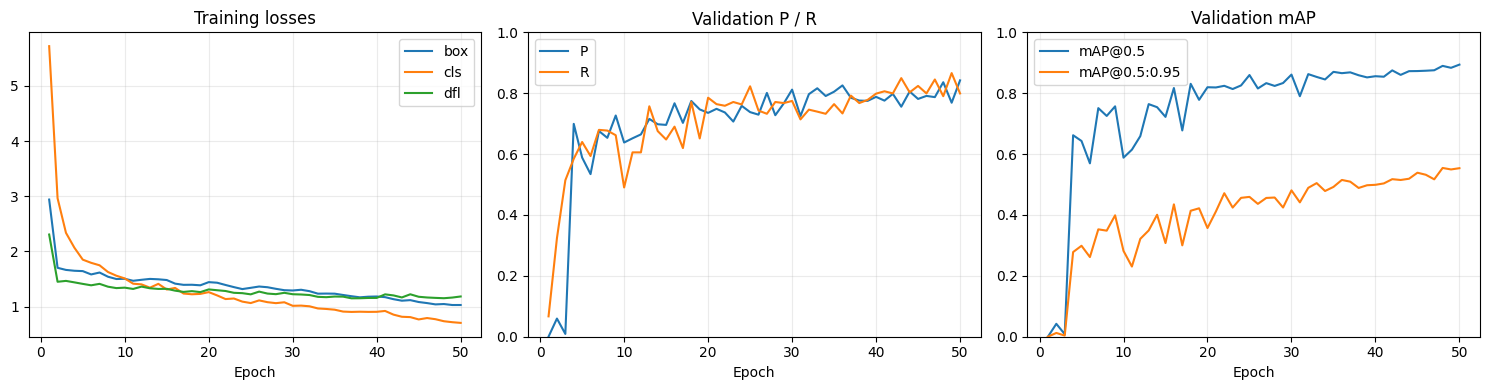

Epochs run: 50 | best epoch (by mAP50-95, approx. Ultralytics fitness): 48
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2792.3±962.3 MB/s, size: 123.7 KB)
val: Scanning /content/ganoderma_final_work/dataset/val/labels.cache... 222 images, 80 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 222/222 71.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.6it/s 2.7s0.2ss
                   all        222        284      0.835      0.784       0.89      0.553
Speed: 2.2ms preprocess, 2.1ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/ganoderma_final_work/val_eval
VALIDATION (used only for checkpoint selection):
  mAP50     : 0.8900
  mAP50-95  : 0.5526
  Precision : 0.8351
  Recall    : 0.7844
  F1        : 0.8089


In [7]:
# ============================================================
# 6. TRAINING CURVES + VALIDATION METRICS OF best.pt
# ============================================================
res_csv = EXP_ROOT / "train_run" / "results.csv"
if res_csv.exists():
    r = pd.read_csv(res_csv)
    r.columns = [c.strip() for c in r.columns]
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for c, lab in [("train/box_loss", "box"), ("train/cls_loss", "cls"), ("train/dfl_loss", "dfl")]:
        ax[0].plot(r["epoch"], r[c], label=lab)
    ax[0].set_title("Training losses"); ax[0].legend()
    ax[1].plot(r["epoch"], r["metrics/precision(B)"], label="P")
    ax[1].plot(r["epoch"], r["metrics/recall(B)"], label="R")
    ax[1].set_title("Validation P / R"); ax[1].set_ylim(0, 1); ax[1].legend()
    ax[2].plot(r["epoch"], r["metrics/mAP50(B)"], label="mAP@0.5")
    ax[2].plot(r["epoch"], r["metrics/mAP50-95(B)"], label="mAP@0.5:0.95")
    ax[2].set_title("Validation mAP"); ax[2].set_ylim(0, 1); ax[2].legend()
    for a in ax:
        a.set_xlabel("Epoch"); a.grid(alpha=.25)
    fig.tight_layout()
    fig.savefig(EXP_ROOT / "final_training_curves.png", dpi=200)
    plt.show()
    best_epoch = int(r.loc[r["metrics/mAP50-95(B)"].idxmax(), "epoch"])
    print("Epochs run:", len(r), "| best epoch (by mAP50-95, approx. Ultralytics fitness):", best_epoch)

best_model = YOLO(str(DRIVE_BEST))
val_res = best_model.val(data=str(DATA_YAML), split="val", imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                         conf=EVAL_CONF, iou=EVAL_IOU, max_det=EVAL_MAXDET,
                         project=str(LOCAL_WORK), name="val_eval", exist_ok=True, plots=True, verbose=False)
val_metrics = extract_metrics(val_res)
write_json(val_metrics, EXP_ROOT / "val_metrics.json")
print("VALIDATION (used only for checkpoint selection):")
for k, v in val_metrics.items():
    print(f"  {k:10s}: {v:.4f}")

In [8]:
# ============================================================
# 7. METRIC + BOOTSTRAP HELPERS (Ultralytics-style AP)
# ============================================================
# Reproduces the Ultralytics detection metric logic (greedy IoU matching at 10 IoU thresholds,
# 101-point interpolated AP, P/R at the max-F1 confidence) so that the 42-image test set can be
# resampled for bootstrap confidence intervals. Section 8 prints both values side by side.
IOUV = np.linspace(0.5, 0.95, 10)
_trapz = getattr(np, "trapezoid", None) or np.trapz

def box_iou_np(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(-1)
    area_a = (a[:, 2:] - a[:, :2]).prod(-1)
    area_b = (b[:, 2:] - b[:, :2]).prod(-1)
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def match_predictions(gt_xyxy, pred_xyxy):
    correct = np.zeros((len(pred_xyxy), len(IOUV)), dtype=bool)
    iou = box_iou_np(gt_xyxy, pred_xyxy)            # (n_gt, n_pred)
    for k, t in enumerate(IOUV):
        g, p = np.nonzero(iou >= t)
        if g.size:
            m = np.stack([g, p, iou[g, p]], 1)
            if g.size > 1:
                m = m[m[:, 2].argsort()[::-1]]
                m = m[np.unique(m[:, 1], return_index=True)[1]]
                m = m[np.unique(m[:, 0], return_index=True)[1]]
            correct[m[:, 1].astype(int), k] = True
    return correct

def compute_ap(recall, precision):
    mrec = np.concatenate(([0.0], recall, [recall[-1] if len(recall) else 1.0], [1.0]))
    mpre = np.concatenate(([1.0], precision, [0.0], [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)
    return float(_trapz(np.interp(x, mrec, mpre), x))

def smooth(y, f=0.05):
    nf = round(len(y) * f * 2) // 2 + 1
    p = np.ones(nf // 2)
    yp = np.concatenate((p * y[0], y, p * y[-1]), 0)
    return np.convolve(yp, np.ones(nf) / nf, mode="valid")

def detection_metrics(tp, conf, n_gt):
    # tp: (N_pred, 10) bool, conf: (N_pred,), n_gt: int  -> dict of single-class metrics
    if n_gt == 0:
        return None
    if len(conf) == 0:
        return {"mAP50": 0.0, "mAP50-95": 0.0, "Precision": 0.0, "Recall": 0.0, "F1": 0.0}
    order = np.argsort(-conf)
    tp, conf = tp[order], conf[order]
    tpc = tp.cumsum(0)
    fpc = (1 - tp).cumsum(0)
    recall = tpc / (n_gt + 1e-16)
    precision = tpc / (tpc + fpc)
    ap = np.array([compute_ap(recall[:, j], precision[:, j]) for j in range(tp.shape[1])])
    x = np.linspace(0, 1, 1000)
    r_curve = np.interp(-x, -conf, recall[:, 0], left=0)
    p_curve = np.interp(-x, -conf, precision[:, 0], left=1)
    f1_curve = 2 * p_curve * r_curve / (p_curve + r_curve + 1e-16)
    i = int(smooth(f1_curve, 0.1).argmax())
    p, r = float(p_curve[i]), float(r_curve[i])
    return {"mAP50": float(ap[0]), "mAP50-95": float(ap.mean()), "Precision": p, "Recall": r,
            "F1": 2 * p * r / (p + r + 1e-16), "best_conf": float(x[i])}

def yolo_labels_to_xyxy(label_path, w, h):
    if not Path(label_path).exists():
        return np.zeros((0, 4))
    rows = [list(map(float, l.split()[1:5])) for l in open(label_path) if l.strip()]
    if not rows:
        return np.zeros((0, 4))
    a = np.array(rows)
    return np.stack([(a[:, 0] - a[:, 2] / 2) * w, (a[:, 1] - a[:, 3] / 2) * h,
                     (a[:, 0] + a[:, 2] / 2) * w, (a[:, 1] + a[:, 3] / 2) * h], 1)

def bootstrap_ci(per_image, n_boot, seed=FINAL_SEED):
    rng = np.random.default_rng(seed)
    n = len(per_image)
    samples = []
    for _ in tqdm(range(n_boot), desc="bootstrap"):
        idx = rng.integers(0, n, n)
        tp = np.concatenate([per_image[i]["tp"] for i in idx]) if n else np.zeros((0, 10), bool)
        cf = np.concatenate([per_image[i]["conf"] for i in idx])
        ng = int(sum(per_image[i]["n_gt"] for i in idx))
        m = detection_metrics(tp, cf, ng)
        if m is not None:
            samples.append(m)
    df = pd.DataFrame(samples)
    keys = ["mAP50", "mAP50-95", "Precision", "Recall", "F1"]
    return {k: {"ci95_low": float(df[k].quantile(0.025)), "ci95_high": float(df[k].quantile(0.975)),
                "boot_sd": float(df[k].std(ddof=1))} for k in keys}, len(df)

# quick self-check on a toy example
_g = np.array([[0, 0, 10, 10], [20, 20, 30, 30]], float)
_p = np.array([[0, 0, 10, 10], [21, 21, 30, 30], [50, 50, 60, 60]], float)
_tp = match_predictions(_g, _p)
_m = detection_metrics(_tp, np.array([0.9, 0.8, 0.3]), 2)
assert _tp[0].all() and not _tp[2].any() and abs(_m["mAP50"] - 1.0) < 0.02
print("metric helpers OK:", {k: round(v, 3) for k, v in _m.items()})

metric helpers OK: {'mAP50': 0.995, 'mAP50-95': 0.845, 'Precision': 0.975, 'Recall': 1.0, 'F1': 0.987, 'best_conf': 0.762}


In [9]:
# ============================================================
# 8. ONE-TIME EVALUATION ON THE 42-IMAGE INDEPENDENT TEST SET
# ============================================================
TEST_LOCK = EXP_ROOT / "TEST_EVAL_LOCK.json"

if TEST_LOCK.exists() and not ALLOW_TEST_REEVAL:
    test_record = json.load(open(TEST_LOCK))
    print("Independent test was ALREADY evaluated on", test_record["evaluated_at"])
    print("Showing the stored result (set ALLOW_TEST_REEVAL=True only if you have a documented reason).")
elif not RUN_TEST_EVAL:
    test_record = None
    print("RUN_TEST_EVAL=False -> independent test not evaluated.")
else:
    best_model = YOLO(str(DRIVE_BEST))

    # (a) official Ultralytics evaluation
    test_res = best_model.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                              conf=EVAL_CONF, iou=EVAL_IOU, max_det=EVAL_MAXDET,
                              project=str(LOCAL_WORK), name="test_eval", exist_ok=True,
                              plots=True, verbose=False)
    ul_metrics = extract_metrics(test_res)

    # (b) per-image predictions -> own metrics + bootstrap CI
    test_img_dir = DATASET_DIR / "test" / "images"
    test_lbl_dir = DATASET_DIR / "test" / "labels"
    per_image, pred_rows = [], []
    for res in best_model.predict(source=str(test_img_dir), imgsz=IMGSZ, conf=EVAL_CONF, iou=EVAL_IOU,
                                  max_det=EVAL_MAXDET, device=DEVICE, stream=True, verbose=False):
        h, w = res.orig_shape
        stem = Path(res.path).stem
        gt = yolo_labels_to_xyxy(test_lbl_dir / f"{stem}.txt", w, h)
        pb = res.boxes.xyxy.cpu().numpy() if len(res.boxes) else np.zeros((0, 4))
        pc = res.boxes.conf.cpu().numpy() if len(res.boxes) else np.zeros((0,))
        tp = match_predictions(gt, pb)
        per_image.append({"image": Path(res.path).name, "tp": tp, "conf": pc, "n_gt": len(gt)})
        for b, c, t in zip(pb, pc, tp):
            pred_rows.append({"image": Path(res.path).name, "x1": b[0], "y1": b[1], "x2": b[2], "y2": b[3],
                              "conf": float(c), "tp_iou50": bool(t[0])})

    assert len(per_image) == len(test_df), (len(per_image), len(test_df))
    n_gt_total = int(sum(p["n_gt"] for p in per_image))
    own = detection_metrics(np.concatenate([p["tp"] for p in per_image]),
                            np.concatenate([p["conf"] for p in per_image]), n_gt_total)
    ci, n_valid = bootstrap_ci(per_image, N_BOOTSTRAP)

    pd.DataFrame(pred_rows).to_csv(EXP_ROOT / "test_predictions.csv", index=False)
    test_record = {
        "evaluated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        "checkpoint": str(DRIVE_BEST),
        "images": len(per_image), "gt_boxes": n_gt_total,
        "protocol": {"conf": EVAL_CONF, "nms_iou": EVAL_IOU, "max_det": EVAL_MAXDET, "imgsz": IMGSZ},
        "ultralytics_metrics": ul_metrics,
        "reimplemented_metrics": own,
        "bootstrap": {"n_resamples": n_valid, "ci95": ci},
    }
    write_json(test_record, TEST_LOCK)
    print("Test result written and LOCKED:", TEST_LOCK)

if test_record is not None:
    ul, own, ci = (test_record["ultralytics_metrics"], test_record["reimplemented_metrics"],
                   test_record["bootstrap"]["ci95"])
    rows = [{"Metric": k, "Ultralytics": round(ul[k], 4), "Re-impl.": round(own[k], 4),
             "95% CI": f"[{ci[k]['ci95_low']:.3f}, {ci[k]['ci95_high']:.3f}]"}
            for k in ["mAP50", "mAP50-95", "Precision", "Recall", "F1"]]
    print(f"\nINDEPENDENT TEST ({test_record['images']} images, {test_record['gt_boxes']} boxes)")
    print(pd.DataFrame(rows).to_string(index=False))
    print("\nReport the Ultralytics values as the point estimate and the bootstrap interval as 95% CI.")
    print("Small Ultralytics vs re-implementation differences (< ~0.01) come from interpolation details.")

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2589.3±866.6 MB/s, size: 118.7 KB)
val: Scanning /content/ganoderma_final_work/dataset/test/labels... 42 images, 16 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 42/42 1.7Kit/s 0.0s
val: New cache created: /content/ganoderma_final_work/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.9it/s 1.0s1.8s
                   all         42         50      0.791       0.58      0.715      0.416
Speed: 3.8ms preprocess, 5.6ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to /content/ganoderma_final_work/test_eval


bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

Test result written and LOCKED: /content/drive/MyDrive/ganoderma/experiments/final_yolov8n_v1/TEST_EVAL_LOCK.json

INDEPENDENT TEST (42 images, 50 boxes)
   Metric  Ultralytics  Re-impl.         95% CI
    mAP50       0.7146    0.6569 [0.549, 0.780]
 mAP50-95       0.4158    0.3791 [0.307, 0.468]
Precision       0.7908    0.7602 [0.679, 0.867]
   Recall       0.5800    0.6340 [0.472, 0.778]
       F1       0.6692    0.6914 [0.581, 0.774]

Report the Ultralytics values as the point estimate and the bootstrap interval as 95% CI.
Small Ultralytics vs re-implementation differences (< ~0.01) come from interpolation details.


In [ ]:
# ============================================================
# 9. EXPORT STATIC ONNX (1x3x640x640) + PyTorch vs ONNX CHECK
# ============================================================
import onnxruntime as ort

ONNX_DIR = EXP_ROOT / "onnx"
ONNX_DIR.mkdir(parents=True, exist_ok=True)

export_model = YOLO(str(DRIVE_BEST))
onnx_path = Path(export_model.export(format="onnx", imgsz=IMGSZ, dynamic=False, simplify=True,
                                     opset=ONNX_OPSET, batch=1, device="cpu"))
shutil.copy2(onnx_path, ONNX_DIR / "final_yolov8n.onnx")
print("ONNX saved:", ONNX_DIR / "final_yolov8n.onnx")

sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
inp = sess.get_inputs()[0]
print("ONNX input :", inp.name, inp.shape)
print("ONNX output:", [(o.name, o.shape) for o in sess.get_outputs()])

def letterbox_tensor(path, size=IMGSZ):
    img = cv2.imread(str(path))
    h, w = img.shape[:2]
    s = size / max(h, w)
    nh, nw = int(round(h * s)), int(round(w * s))
    canvas = np.full((size, size, 3), 114, np.uint8)
    top, left = (size - nh) // 2, (size - nw) // 2
    canvas[top:top + nh, left:left + nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    x = canvas[:, :, ::-1].transpose(2, 0, 1)[None].astype(np.float32) / 255.0
    return np.ascontiguousarray(x)

torch_model = YOLO(str(DRIVE_BEST)).model.float().eval().cpu()
check_imgs = sorted((DATASET_DIR / "val" / "images").iterdir())[:5]   # validation images, not test
max_diffs = []
for p in check_imgs:
    x = letterbox_tensor(p)
    with torch.no_grad():
        yt = torch_model(torch.from_numpy(x))
    yt = (yt[0] if isinstance(yt, (list, tuple)) else yt).numpy()
    yo = sess.run(None, {inp.name: x})[0]
    max_diffs.append(float(np.abs(yt - yo).max()))
print("PyTorch vs ONNX max |diff| per image:", [round(d, 5) for d in max_diffs])
print("Score-channel max |diff|:", float(np.abs(yt[:, 4:] - yo[:, 4:]).max()))
write_json({"onnx": str(ONNX_DIR / "final_yolov8n.onnx"), "opset": ONNX_OPSET,
            "input": [inp.name, inp.shape], "outputs": [(o.name, o.shape) for o in sess.get_outputs()],
            "torch_vs_onnx_max_abs_diff": max_diffs}, ONNX_DIR / "onnx_check.json")

In [ ]:
# ============================================================
# 10. CALIBRATION IMAGES FOR INT8 / QNN (final TRAIN split only)
# ============================================================
CALIB_DIR = EXP_ROOT / "calibration_images"
if CALIB_DIR.exists():
    shutil.rmtree(CALIB_DIR)
CALIB_DIR.mkdir(parents=True)

calib_df = train_df.sample(n=min(CALIB_N, len(train_df)), random_state=FINAL_SEED)
for _, row in calib_df.iterrows():
    shutil.copy2(LOCAL_DATASET / row["rel_image"], CALIB_DIR / f"{row['source_split']}__{row['filename']}")
calib_df[["uid", "rel_image", "positive", "n_boxes"]].to_csv(EXP_ROOT / "calibration_manifest.csv", index=False)
(EXP_ROOT / "calibration_list.txt").write_text(
    "\n".join(sorted(p.name for p in CALIB_DIR.iterdir())) + "\n")
assert not set(calib_df["uid"]) & set(test_df["uid"])
print(f"{len(calib_df)} calibration images ({int(calib_df['positive'].sum())} positive) -> {CALIB_DIR}")

In [ ]:
# ============================================================
# 11. FINAL SUMMARY
# ============================================================
summary = {
    "experiment": EXP_NAME,
    "recipe": {"model": MODEL_CFG, "epochs": EPOCHS, "imgsz": IMGSZ, "batch": BATCH,
               "patience": PATIENCE, "seed": FINAL_SEED, "grouping": GROUPING,
               "synthetic_data": False},
    "split": split_summary.to_dict(orient="records"),
    "validation_metrics": val_metrics,
    "independent_test": test_record,
    "artifacts": {
        "best_pt": str(DRIVE_BEST), "last_pt": str(DRIVE_LAST),
        "onnx": str(EXP_ROOT / "onnx" / "final_yolov8n.onnx"),
        "calibration_dir": str(EXP_ROOT / "calibration_images"),
        "train_manifest": str(SPLITS_DIR / "final_train.csv"),
        "val_manifest": str(SPLITS_DIR / "final_val.csv"),
    },
}
write_json(summary, EXP_ROOT / "final_summary.json")
print(json.dumps({k: summary[k] for k in ["recipe", "split", "validation_metrics"]}, indent=2))
print("\nAll outputs saved to:", EXP_ROOT)

## What to do next

1. **Paper numbers:** use `TEST_EVAL_LOCK.json` — Ultralytics metrics as the point estimate, bootstrap 95% CI
   alongside. Report it separately from the 5-fold CV mean ± SD (different protocols).
2. **Deployment with the SAME checkpoint:** convert `onnx/final_yolov8n.onnx` with onnx2qnn
   (output split → INT8 QNN context binary), using `calibration_images/` for calibration.
   Then rerun the static 42-image evaluation (FP32 ORT CPU, INT8 ORT CPU, QNN HTP NPU), timing,
   power and the RTSP test so that every table in the paper refers to this one model.
3. **Do not retrain after looking at the test result.** If you change the recipe (e.g. 100 epochs,
   `GROUPING="near"`), rerun the 5-fold CV with the same change first, then train a new final model in a
   new `EXP_NAME` and document it.

In [10]:
# DIAGNOSTIC: Ultralytics val at exactly 640x640 (no rect padding) — does NOT touch the lock
diag = YOLO(str(DRIVE_BEST)).val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=1,
                                 rect=False, conf=EVAL_CONF, iou=EVAL_IOU, max_det=EVAL_MAXDET,
                                 device=DEVICE, project=str(LOCAL_WORK), name="test_eval_640",
                                 exist_ok=True, plots=False, verbose=False)
d = extract_metrics(diag); print(d)
write_json({"note": "rect=False, 640x640 input; measurement check only", **d},
           EXP_ROOT / "test_eval_640_diagnostic.json")

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3382.9±944.0 MB/s, size: 116.2 KB)
val: Scanning /content/ganoderma_final_work/dataset/test/labels.cache... 42 images, 16 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 42/42 11.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 52.5it/s 0.8s0.1s
                   all         42         50       0.76      0.634      0.657      0.379
Speed: 0.9ms preprocess, 7.5ms inference, 0.0ms loss, 1.0ms postprocess per image
{'mAP50': 0.6568595444686645, 'mAP50-95': 0.3791384921647903, 'Precision': 0.7601618259562848, 'Recall': 0.6339973285934449, 'F1': 0.6913709462537022}


In [11]:
dev_df["src_group"] = dev_df["filename"].str.split(".rf.").str[0]
print(dev_df["src_group"].nunique(), "source groups")   # ~433 hole confirmed
print(dev_df.groupby("source_split")["src_group"].nunique())

381 source groups
source_split
train    297
valid    101
Name: src_group, dtype: int64


In [12]:
test_df["src_group"] = test_df["filename"].str.split(".rf.").str[0]
dt = set(dev_df["src_group"]) & set(test_df["src_group"])
print("dev<->test shared source names:", len(dt), sorted(dt)[:20])
tv = (set(dev_df.loc[dev_df.source_split == "train", "src_group"])
      & set(dev_df.loc[dev_df.source_split == "valid", "src_group"]))
print("train<->valid shared:", len(tv), sorted(tv)[:10])
sz = dev_df.groupby("src_group").size()
print(sz.describe()); print(sz.sort_values().tail(5))

dev<->test shared source names: 12 ['GUB_AFD_IV_BLOK_16T10_PNG', 'GUB_AFD_IV_BLOK_16T11_PNG', 'GUB_AFD_IV_BLOK_16T13_PNG', 'GUB_AFD_IV_BLOK_16T2_PNG', 'GUB_AFD_IV_BLOK_16T32_PNG', 'GUB_AFD_IV_BLOK_16T40_PNG', 'GUB_AFD_IV_BLOK_16T44_PNG', 'GUB_AFD_IV_BLOK_16T47_PNG', 'GUB_AFD_IV_BLOK_16T48_PNG', 'GUB_AFD_IV_BLOK_16T53_PNG', 'GUB_AFD_IV_BLOK_16T5_PNG', 'GUB_AFD_IV_BLOK_16T60_PNG']
train<->valid shared: 17 ['GUB_AFD_IV_BLOK_16T12_PNG', 'GUB_AFD_IV_BLOK_16T16_PNG', 'GUB_AFD_IV_BLOK_16T18_PNG', 'GUB_AFD_IV_BLOK_16T21_PNG', 'GUB_AFD_IV_BLOK_16T23_PNG', 'GUB_AFD_IV_BLOK_16T26_PNG', 'GUB_AFD_IV_BLOK_16T28_PNG', 'GUB_AFD_IV_BLOK_16T31_PNG', 'GUB_AFD_IV_BLOK_16T36_PNG', 'GUB_AFD_IV_BLOK_16T37_PNG']
count    381.000000
mean       2.863517
std        1.282373
min        1.000000
25%        3.000000
50%        3.000000
75%        3.000000
max        6.000000
dtype: float64
src_group
GUB_AFD_IV_BLOK_16T63_PNG    6
GUB_AFD_IV_BLOK_16T6_PNG     6
GUB_AFD_IV_BLOK_16T45_PNG    6
GUB_AFD_IV_BLOK_16T34_PN

In [13]:
# FLIP-AWARE TEST vs DEV AUDIT (no training, no test metrics)
def phs(path):
    im = Image.open(path).convert("RGB")
    return [imagehash.phash(v) for v in (im, ImageOps.mirror(im), ImageOps.flip(im),
                                         ImageOps.flip(ImageOps.mirror(im)))]

index_df["src_group"] = index_df["filename"].str.split(".rf.").str[0]
dev = index_df[index_df.source_split.isin(["train", "valid"])].copy()
tst = index_df[index_df.source_split == "test"].copy()
dev_h = {r.uid: phs(LOCAL_DATASET / r.rel_image) for r in tqdm(list(dev.itertuples()), desc="dev hashes")}

rows = []
for t in tst.itertuples():
    th = imagehash.phash(Image.open(LOCAL_DATASET / t.rel_image).convert("RGB"))
    d_any = {uid: min(th - h for h in hs) for uid, hs in dev_h.items()}
    closest = min(d_any, key=d_any.get)
    same = dev[dev.src_group == t.src_group]
    rows.append({"test": t.filename, "src_group": t.src_group,
                 "n_same_name_in_dev": len(same),
                 "same_name_splits": ",".join(sorted(set(same.source_split))),
                 "min_dist_same_name": min((d_any[u] for u in same.uid), default=None),
                 "min_dist_any_dev": d_any[closest], "closest_dev": closest})
rep = pd.DataFrame(rows).sort_values("min_dist_any_dev")
rep.to_csv(EXP_ROOT / "audits" / "test_vs_dev_flip_aware.csv", index=False)
print(rep.to_string(index=False))

# side-by-side montages: [test | same-name dev images | closest dev image]
MONT = EXP_ROOT / "audits" / "test_dev_montages"; MONT.mkdir(parents=True, exist_ok=True)
dev_by_uid = dev.set_index("uid")
for r in rep[(rep.n_same_name_in_dev > 0) | (rep.min_dist_any_dev <= 12)].itertuples():
    uids = list(dev.loc[dev.src_group == r.src_group, "uid"])
    if r.closest_dev not in uids:
        uids.append(r.closest_dev)
    paths = [LOCAL_DATASET / "test" / "images" / r.test] + [LOCAL_DATASET / dev_by_uid.loc[u, "rel_image"] for u in uids]
    ims = [Image.open(p).convert("RGB").resize((256, 256)) for p in paths]
    m = Image.new("RGB", (256 * len(ims), 256), "white")
    for i, im in enumerate(ims):
        m.paste(im, (256 * i, 0))
    m.save(MONT / f"{Path(r.test).stem}.jpg")
print("montages ->", MONT)

dev hashes:   0%|          | 0/1091 [00:00<?, ?it/s]

                                                                     test                         src_group  n_same_name_in_dev same_name_splits  min_dist_same_name  min_dist_any_dev                                                                      closest_dev
         GUB_AFD_IV_BLOK_16T2_PNG.rf.2674c1fc207b66f542d54a2825d4a8f6.jpg          GUB_AFD_IV_BLOK_16T2_PNG                   3            train                24.0                14         train::GUB_AFD_IV_BLOK_16V12_PNG.rf.c1d2232a7762ef4f5e097403640d5729.jpg
        GUB_AFD_IV_BLOK_16U62_PNG.rf.60fa9ef1a241fe01730b5ffc39a733be.jpg         GUB_AFD_IV_BLOK_16U62_PNG                   0                                  NaN                14         train::GUB_AFD_IV_BLOK_16T17_PNG.rf.869c0d71600eb4970bfed9efe305bb1a.jpg
        GUB_AFD_IV_BLOK_16S36_PNG.rf.43b34aa195b9b42400991608f0dc5436.jpg         GUB_AFD_IV_BLOK_16S36_PNG                   0                                  NaN                16         train::GUB_AFD_IV